In [ ]:
# ============================================================
# DOSM DATATHON 2026
# SUSTAINABLE TOURISM READINESS IN MALAYSIA
# ============================================================

!pip -q install pandas numpy matplotlib seaborn scikit-learn openpyxl pyarrow requests

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import os
import warnings

warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    silhouette_score,
    classification_report,
    confusion_matrix,
    accuracy_score
)
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.3f}".format)

print("Environment ready.")

Environment ready.


In [ ]:
# ============================================================
# PROJECT FOLDERS
# ============================================================

os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)
os.makedirs("outputs", exist_ok=True)
os.makedirs("models", exist_ok=True)

print("Folders created.")

Folders created.


In [ ]:
# ============================================================
# OFFICIAL OPENDOSM DATASETS
# ============================================================

URLS = {

    # Economic
    "gdp":
    "https://storage.dosm.gov.my/gdp/gdp_state_real_supply.csv", # Annual Real GDP by State & Economic Sector : https://open.dosm.gov.my/data-catalogue/gdp_state_real_supply?series=abs&state=johor&sector=p1&visual=table

    # Household income / poverty / inequality / expenditure
    "hies":
    "https://storage.dosm.gov.my/hies/hies_state.csv", # Household Income and Expenditure: States : https://open.dosm.gov.my/data-catalogue/hies_state?utm_source=chatgpt.com

    # Labour
    "labour":
    "https://storage.dosm.gov.my/labour/lfs_state_sex.csv", # Annual Principal Labour Force Statistics by State & Sex : https://open.dosm.gov.my/data-catalogue/lfs_state_sex?utm_source=chatgpt.com&visual=u_rate

    # Population
    "population":
    "https://storage.dosm.gov.my/population/population_state.csv", # Population Table: States : https://open.dosm.gov.my/data-catalogue/population_state?utm_source=chatgpt.com

    # CPI
    "cpi":
    "https://storage.dosm.gov.my/cpi/cpi_2d_state.csv", # Monthly CPI by State & Division (2-digit) : https://open.dosm.gov.my/data-catalogue/cpi_state?utm_source=chatgpt.com

    # Environment
    "forest":
    "https://storage.data.gov.my/environment/forest_reserve_state.csv", # Area of Permanent Forest Reserves by State : https://open.dosm.gov.my/data-catalogue/forest_reserve_state

    "water_access":
    "https://storage.data.gov.my/water/water_access.csv", # Access to Treated Water by State & Strata : https://open.dosm.gov.my/data-catalogue/water_access

    "water_consumption":
    "https://storage.data.gov.my/water/water_consumption.csv" # Water Consumption by State and Sector : https://open.dosm.gov.my/data-catalogue/water_consumption
}

for name, url in URLS.items():
    print(name, ":", url)

gdp : https://storage.dosm.gov.my/gdp/gdp_state_real_supply.csv
hies : https://storage.dosm.gov.my/hies/hies_state.csv
labour : https://storage.dosm.gov.my/labour/lfs_state_sex.csv
population : https://storage.dosm.gov.my/population/population_state.csv
cpi : https://storage.dosm.gov.my/cpi/cpi_2d_state.csv
forest : https://storage.data.gov.my/environment/forest_reserve_state.csv
water_access : https://storage.data.gov.my/water/water_access.csv
water_consumption : https://storage.data.gov.my/water/water_consumption.csv


In [ ]:
# ============================================================
# DOWNLOAD DATA
# ============================================================

raw_data = {}

for name, url in URLS.items():

    try:

        print(f"Downloading {name}...")

        df = pd.read_csv(url)

        raw_data[name] = df

        df.to_csv(
            f"data/raw/{name}.csv",
            index=False
        )

        print(
            f"   ✓ {name}: "
            f"{df.shape[0]:,} rows × "
            f"{df.shape[1]} columns"
        )

    except Exception as e:

        print(
            f"   ✗ Failed: {name}"
        )

        print(e)

   ✓ gdp: 2,163 rows × 5 columns
   ✓ hies: 32 rows × 7 columns
   ✓ labour: 1,732 rows × 10 columns
   ✓ population: 270,063 rows × 6 columns
   ✓ cpi: 44,576 rows × 4 columns
   ✓ forest: 323 rows × 3 columns
   ✓ water_access: 1,035 rows × 4 columns
   ✓ water_consumption: 600 rows × 4 columns


In [ ]:
# ============================================================
# INSPECT DATA
# ============================================================

for name, df in raw_data.items():

    print("\n" + "=" * 70)

    print(name.upper())

    print("=" * 70)

    print(df.columns.tolist())

    display(df.head(3))


GDP
['series', 'date', 'state', 'sector', 'value']


,series,date,state,sector,value
0,abs,2015-01-01,Johor,p0,"110,002.221"
1,abs,2015-01-01,Johor,p1,"15,610.314"
2,abs,2015-01-01,Johor,p2,475.640



HIES
['date', 'state', 'income_mean', 'income_median', 'expenditure_mean', 'gini', 'poverty']


,date,state,income_mean,income_median,expenditure_mean,gini,poverty
0,2022-01-01,Johor,8517,6879,5342,0.366,4.600
1,2024-01-01,Johor,9484,7712,5927,0.348,2.500
2,2022-01-01,Kedah,5550,4402,3765,0.359,9.000



LABOUR
['state', 'sex', 'date', 'lf', 'lf_employed', 'lf_unemployed', 'lf_outside', 'p_rate', 'u_rate', 'ep_ratio']


...

,date,state,area
0,2003-01-01,Johor,"356,922.000"
1,2003-01-01,Kedah,"344,530.000"
2,2003-01-01,Kelantan,"629,687.000"



WATER_ACCESS
['state', 'strata', 'date', 'proportion']


,state,strata,date,proportion
0,Malaysia,overall,2000-01-01,92.000
1,Malaysia,overall,2001-01-01,92.700
2,Malaysia,overall,2002-01-01,93.200



WATER_CONSUMPTION
['state', 'sector', 'date', 'value']


,state,sector,date,value
0,Malaysia,domestic,2003-01-01,4394
1,Malaysia,domestic,2004-01-01,4770
2,Malaysia,domestic,2005-01-01,4992


In [ ]:
# ============================================================
# STATE STANDARDISATION
# ============================================================

STATE_MAP = {

    "Johor": "Johor",
    "Johore": "Johor",

    "Kedah": "Kedah",

    "Kelantan": "Kelantan",

    "Melaka": "Melaka",
    "Malacca": "Melaka",

    "Negeri Sembilan": "Negeri Sembilan",

    "Pahang": "Pahang",

    "Pulau Pinang": "Pulau Pinang",
    "Penang": "Pulau Pinang",

    "Perak": "Perak",

    "Perlis": "Perlis",

    "Selangor": "Selangor",

    "Terengganu": "Terengganu",

    "Sabah": "Sabah",

    "Sarawak": "Sarawak",

    "W.P. Kuala Lumpur": "W.P. Kuala Lumpur",
    "Kuala Lumpur": "W.P. Kuala Lumpur",

    "W.P. Putrajaya": "W.P. Putrajaya",
    "Putrajaya": "W.P. Putrajaya",

    "W.P. Labuan": "W.P. Labuan",
    "Labuan": "W.P. Labuan"
}


def clean_state_column(df):

    df = df.copy()

    if "state" in df.columns:

        df["state"] = (
            df["state"]
            .astype(str)
            .str.strip()
            .replace(STATE_MAP)
        )

    return df


for name in raw_data:

    raw_data[name] = clean_state_column(
        raw_data[name]
    )

print("State names standardised.")

State names standardised.


In [ ]:
# ============================================================
# DATE STANDARDISATION
# ============================================================

def add_year(df):

    df = df.copy()

    if "date" in df.columns:

        df["date"] = pd.to_datetime(
            df["date"],
            errors="coerce"
        )

        df["year"] = df["date"].dt.year

    return df


for name in raw_data:

    raw_data[name] = add_year(
        raw_data[name]
    )

In [ ]:
hies = raw_data["hies"].copy()

print(hies.columns.tolist())

display(hies.head())

['date', 'state', 'income_mean', 'income_median', 'expenditure_mean', 'gini', 'poverty', 'year']


,date,state,income_mean,income_median,expenditure_mean,gini,poverty,year
0,2022-01-01,Johor,8517,6879,5342,0.366,4.600,2022
1,2024-01-01,Johor,9484,7712,5927,0.348,2.500,2024
2,2022-01-01,Kedah,5550,4402,3765,0.359,9.000,2022
3,2024-01-01,Kedah,5793,4895,4028,0.334,8.400,2024
4,2022-01-01,Kelantan,4885,3614,3505,0.385,13.200,2022


In [ ]:
# ============================================================
# HIES — 2022
# ============================================================

hies_2022 = hies[
    hies["year"] == 2022
].copy()

print(
    "HIES 2022:",
    hies_2022.shape
)

display(hies_2022.head())

HIES 2022: (16, 8)


,date,state,income_mean,income_median,expenditure_mean,gini,poverty,year
0,2022-01-01,Johor,8517,6879,5342,0.366,4.600,2022
2,2022-01-01,Kedah,5550,4402,3765,0.359,9.000,2022
4,2022-01-01,Kelantan,4885,3614,3505,0.385,13.200,2022
6,2022-01-01,Melaka,8057,6210,5707,0.370,4.200,2022
8,2022-01-01,Negeri Sembilan,6788,5226,4678,0.369,4.400,2022


In [ ]:
# ============================================================
# POPULATION
# ============================================================

population = raw_data["population"].copy()

population_2022 = population[
    (population["year"] == 2022) &
    (population["sex"] == "both") &
    (population["age"] == "overall") &
    (population["ethnicity"] == "overall")
].copy()

population_2022 = population_2022[
    ["state", "population"]
]

display(population_2022.head())

,state,population
15819,Johor,"4,028.300"
33633,Kedah,"2,163.100"
51447,Kelantan,"1,830.600"
69261,Melaka,"1,008.600"
87075,Negeri Sembilan,"1,207.900"


In [ ]:
# ============================================================
# GDP
# ============================================================

gdp = raw_data["gdp"].copy()

print(gdp.columns.tolist())

display(gdp.head())

for col in gdp.columns:

    if gdp[col].dtype == "object":

        print(
            "\nCOLUMN:",
            col
        )

        print(
            gdp[col]
            .dropna()
            .unique()[:30]
        )

['series', 'date', 'state', 'sector', 'value', 'year']


,series,date,state,sector,value,year
0,abs,2015-01-01,Johor,p0,"110,002.221",2015
1,abs,2015-01-01,Johor,p1,"15,610.314",2015
2,abs,2015-01-01,Johor,p2,475.640,2015
3,abs,2015-01-01,Johor,p3,"32,358.659",2015
4,abs,2015-01-01,Johor,p4,"7,269.160",2015



COLUMN: series
['abs' 'growth_yoy']

COLUMN: state
['Johor' 'Kedah' 'Kelantan' 'Melaka' 'Negeri Sembilan' 'Pahang' 'Perak'
 'Perlis' 'Pulau Pinang' 'Sabah' 'Sarawak' 'Selangor' 'Terengganu'
 'W.P. Kuala Lumpur' 'W.P. Labuan' 'W.P. Putrajaya' 'Supra']

COLUMN: sector
['p0' 'p1' 'p2' 'p3' 'p4' 'p5' 'p6']


In [ ]:
# ============================================================
# GDP PREPARATION
# ============================================================

print(gdp.columns)

Index(['series', 'date', 'state', 'sector', 'value', 'year'], dtype='object')


In [ ]:
gdp_2022 = gdp[
    gdp["year"] == 2022
].copy()

display(gdp_2022.head())

,series,date,state,sector,value,year
735,abs,2022-01-01,Johor,p0,"142,369.692",2022
736,abs,2022-01-01,Johor,p1,"17,402.664",2022
737,abs,2022-01-01,Johor,p2,648.636,2022
738,abs,2022-01-01,Johor,p3,"42,948.216",2022
739,abs,2022-01-01,Johor,p4,"3,962.150",2022


In [ ]:
print(
    gdp_2022["sector"]
    .unique()
)

['p0' 'p1' 'p2' 'p3' 'p4' 'p5' 'p6']


In [ ]:
# Find possible total / overall GDP sector

sector_values = (
    gdp_2022["sector"]
    .dropna()
    .astype(str)
    .unique()
)

print(sector_values)

['p0' 'p1' 'p2' 'p3' 'p4' 'p5' 'p6']


In [ ]:
gdp_total = gdp_2022[
    gdp_2022["sector"] == "p0"
].copy()

display(gdp_total.head())

,series,date,state,sector,value,year
735,abs,2022-01-01,Johor,p0,"142,369.692",2022
742,abs,2022-01-01,Kedah,p0,"50,982.123",2022
749,abs,2022-01-01,Kelantan,p0,"26,934.566",2022
756,abs,2022-01-01,Melaka,p0,"45,579.035",2022
763,abs,2022-01-01,Negeri Sembilan,p0,"50,939.264",2022


In [ ]:
# ============================================================
# GDP PER CAPITA
# ============================================================

gdp_total = gdp_total[
    ["state", "value"]
].rename(
    columns={
        "value": "gdp"
    }
)

gdp_total = gdp_total.merge(
    population_2022,
    on="state",
    how="left"
)

# Population is in thousands
gdp_total["gdp_per_capita"] = (
    gdp_total["gdp"] /
    gdp_total["population"]
)

display(gdp_total)

,state,gdp,population,gdp_per_capita
0,Johor,"142,369.692","4,028.300",35.342
1,Kedah,"50,982.123","2,163.100",23.569
2,Kelantan,"26,934.566","1,830.600",14.714
3,Melaka,"45,579.035","1,008.600",45.190
4,Negeri Sembilan,"50,939.264","1,207.900",42.172
5,Pahang,"61,746.204","1,614.300",38.250
6,Perak,"80,426.886","2,514.400",31.987
7,Perlis,"6,209.957",289.800,21.428
8,Pulau Pinang,"112,281.052","1,740.900",64.496
9,Sabah,"82,106.428","3,414.900",24.044


In [ ]:
# ============================================================
# LABOUR
# ============================================================

labour = raw_data["labour"].copy()

print(labour.columns.tolist())

display(labour.head())

['state', 'sex', 'date', 'lf', 'lf_employed', 'lf_unemployed', 'lf_outside', 'p_rate', 'u_rate', 'ep_ratio', 'year']


,state,sex,date,lf,lf_employed,lf_unemployed,lf_outside,p_rate,u_rate,ep_ratio,year
0,Johor,both,1982-01-01,653.100,630.200,22.900,345.100,65.400,3.500,63.400,1982
1,Johor,both,1983-01-01,650.900,623.700,27.200,344.100,65.400,4.200,60.500,1983
2,Johor,both,1984-01-01,688.200,657.300,30.900,372.100,64.900,4.500,61.700,1984
3,Johor,both,1985-01-01,710.400,672.700,37.600,354.700,66.700,5.300,61.200,1985
4,Johor,both,1986-01-01,751.200,700.400,50.800,367.800,67.100,6.800,61.700,1986


In [ ]:
for col in labour.columns:

    if labour[col].dtype == "object":

        print(
            "\n",
            col,
            ":",
            labour[col]
            .dropna()
            .unique()[:20]
        )


 state : ['Johor' 'Kedah' 'Kelantan' 'Melaka' 'Negeri Sembilan' 'Pahang' 'Perak'
 'Perlis' 'Pulau Pinang' 'Sabah' 'Sarawak' 'Selangor' 'Terengganu'
 'W.P. Kuala Lumpur' 'W.P. Labuan' 'W.P. Putrajaya']

 sex : ['both' 'female' 'male']


In [ ]:
labour_2022 = labour[
    labour["year"] == 2022
].copy()

display(labour_2022.head())

,state,sex,date,lf,lf_employed,lf_unemployed,lf_outside,p_rate,u_rate,ep_ratio,year
38,Johor,both,2022-01-01,"2,013.400","1,949.200",64.200,818.200,71.100,3.200,68.900,2022
78,Johor,female,2022-01-01,659.385,632.959,26.426,639.862,50.751,4.008,48.800,2022
118,Johor,male,2022-01-01,"1,354.004","1,316.199",37.806,178.371,88.360,2.792,86.000,2022
158,Kedah,both,2022-01-01,928.000,900.400,27.600,518.400,64.200,3.000,62.300,2022
198,Kedah,female,2022-01-01,338.265,323.161,15.104,368.136,47.886,4.465,45.800,2022


In [ ]:
if "sex" in labour_2022.columns:

    print(
        labour_2022["sex"].unique()
    )

['both' 'female' 'male']


In [ ]:
if "sex" in labour_2022.columns:

    labour_2022 = labour_2022[
        labour_2022["sex"]
        .astype(str)
        .str.lower()
        .isin([
            "both",
            "overall",
            "all"
        ])
    ]

In [ ]:
# ============================================================
# FOREST RESERVES
# ============================================================

forest = raw_data["forest"].copy()

print(forest.columns.tolist())

display(forest.head())

['date', 'state', 'area', 'year']


,date,state,area,year
0,2003-01-01,Johor,"356,922.000",2003
1,2003-01-01,Kedah,"344,530.000",2003
2,2003-01-01,Kelantan,"629,687.000",2003
3,2003-01-01,Melaka,"5,468.000",2003
4,2003-01-01,Negeri Sembilan,"165,639.000",2003


In [ ]:
forest_latest = (
    forest
    .sort_values("year")
    .groupby("state")
    .tail(1)
    .copy()
)

forest_latest = forest_latest[
    ["state", "area"]
].rename(
    columns={
        "area": "forest_reserve_area"
    }
)

display(forest_latest.head())

,state,forest_reserve_area
311,Pahang,"1,588,298.000"
312,Perak,"986,848.000"
313,Perlis,"10,629.000"
314,Pulau Pinang,"5,387.000"
315,Sabah,"3,574,468.000"


In [ ]:
# ============================================================
# TREATED WATER ACCESS
# ============================================================

water_access = raw_data[
    "water_access"
].copy()

print(
    water_access.columns.tolist()
)

display(
    water_access.head()
)

['state', 'strata', 'date', 'proportion', 'year']


,state,strata,date,proportion,year
0,Malaysia,overall,2000-01-01,92.000,2000
1,Malaysia,overall,2001-01-01,92.700,2001
2,Malaysia,overall,2002-01-01,93.200,2002
3,Malaysia,overall,2003-01-01,93.700,2003
4,Malaysia,overall,2004-01-01,94.000,2004


In [ ]:
water_access_2022 = water_access[
    (water_access["year"] == 2022) &
    (
        water_access["strata"]
        .astype(str)
        .str.lower()
        == "overall"
    )
].copy()

water_access_2022 = water_access_2022[
    ["state", "proportion"]
].rename(
    columns={
        "proportion":
        "treated_water_access"
    }
)

display(
    water_access_2022
)

,state,treated_water_access
22,Malaysia,94.900
91,Johor,99.900
160,Kedah,98.300
229,Kelantan,73.900
298,Melaka,100.000
367,Negeri Sembilan,99.900
436,Pahang,98.000
505,Perak,99.600
574,Perlis,99.500
643,Pulau Pinang,99.900


In [ ]:
# ============================================================
# WATER CONSUMPTION
# ============================================================

water = raw_data[
    "water_consumption"
].copy()

print(
    water.columns.tolist()
)

display(
    water.head()
)

['state', 'sector', 'date', 'value', 'year']


,state,sector,date,value,year
0,Malaysia,domestic,2003-01-01,4394,2003
1,Malaysia,domestic,2004-01-01,4770,2004
2,Malaysia,domestic,2005-01-01,4992,2005
3,Malaysia,domestic,2006-01-01,5025,2006
4,Malaysia,domestic,2007-01-01,5381,2007


In [ ]:
water_2022 = water[
    water["year"] == 2022
].copy()

In [ ]:
water_pivot = (
    water_2022
    .pivot_table(
        index="state",
        columns="sector",
        values="value",
        aggfunc="mean"
    )
    .reset_index()
)

water_pivot.columns.name = None

display(water_pivot)

,state,domestic,nondomestic
0,Johor,867.000,536.000
1,Kedah,560.000,217.000
2,Kelantan,162.000,77.000
3,Malaysia,"7,353.000","4,433.000"
4,Melaka,228.000,190.000
5,Negeri Sembilan,307.000,231.000
6,Pahang,385.000,283.000
7,Perak,699.000,289.000
8,Perlis,80.000,18.000
9,Pulau Pinang,534.000,334.000


In [ ]:
water_pivot = water_pivot.rename(
    columns={
        "domestic":
        "domestic_water_consumption",

        "nondomestic":
        "nondomestic_water_consumption"
    }
)

BUILD MASTER DATASET

In [ ]:
# ============================================================
# MASTER DATASET
# ============================================================

master = hies_2022.copy()

# Keep important HIES variables
hies_columns = [
    "state",
    "income_mean",
    "income_median",
    "expenditure_mean",
    "gini",
    "poverty"
]

master = master[
    [
        c for c in hies_columns
        if c in master.columns
    ]
]

# Population
master = master.merge(
    population_2022,
    on="state",
    how="left"
)

# GDP
master = master.merge(
    gdp_total,
    on="state",
    how="left"
)

# Forest
master = master.merge(
    forest_latest,
    on="state",
    how="left"
)

# Water access
master = master.merge(
    water_access_2022,
    on="state",
    how="left"
)

# Water consumption
master = master.merge(
    water_pivot,
    on="state",
    how="left"
)

print(
    "Master dataset:",
    master.shape
)

display(master)

Master dataset: (29, 14)


,state,income_mean,income_median,expenditure_mean,gini,poverty,population_x,gdp,population_y,gdp_per_capita,forest_reserve_area,treated_water_access,domestic_water_consumption,nondomestic_water_consumption
0,Johor,8517,6879,5342,0.366,4.600,"4,028.300","142,369.692","4,028.300",35.342,"334,502.000",99.900,867.000,536.000
1,Johor,8517,6879,5342,0.366,4.600,"4,028.300",8.500,"4,028.300",0.002,"334,502.000",99.900,867.000,536.000
2,Kedah,5550,4402,3765,0.359,9.000,"2,163.100","50,982.123","2,163.100",23.569,"341,976.000",98.300,560.000,217.000
3,Kedah,5550,4402,3765,0.359,9.000,"2,163.100",7.300,"2,163.100",0.003,"341,976.000",98.300,560.000,217.000
4,Kelantan,4885,3614,3505,0.385,13.200,"1,830.600","26,934.566","1,830.600",14.714,"629,881.000",73.900,162.000,77.000
5,Kelantan,4885,3614,3505,0.385,13.200,"1,830.600",4.500,"1,830.600",0.002,"629,881.000",73.900,162.000,77.000
6,Melaka,8057,6210,5707,0.370,4.200,"1,008.600","45,579.035","1,008.600",45.190,"5,199.000",100.000,228.000,190.000
7,Melaka,8057,6210,5707,0.370,4.200,"1,008.600",8.900,"1,008.600",0.009,"5,199.000",100.000,228.000,190.000
8,Negeri Sembilan,6788,5226,4678,0.369,4.400,"1,207.900","50,939.264","1,207.900",42.172,"155,143.000",99.900,307.000,231.000
9,Negeri Sembilan,6788,5226,4678,0.369,4.400,"1,207.900",6.600,"1,207.900",0.005,"155,143.000",99.900,307.000,231.000


In [ ]:
print(
    labour_2022.columns.tolist()
)

['state', 'sex', 'date', 'lf', 'lf_employed', 'lf_unemployed', 'lf_outside', 'p_rate', 'u_rate', 'ep_ratio', 'year']


In [ ]:
labour_features = labour_2022[
    ["state", "u_rate", "p_rate"]
].copy()

labour_features = labour_features.rename(
    columns={
        "u_rate":
        "unemployment_rate",

        "p_rate":
        "labour_participation_rate"
    }
)

master = master.merge(
    labour_features,
    on="state",
    how="left"
)

display(master)

,state,income_mean,income_median,expenditure_mean,gini,poverty,population_x,gdp,population_y,gdp_per_capita,forest_reserve_area,treated_water_access,domestic_water_consumption,nondomestic_water_consumption,unemployment_rate,labour_participation_rate
0,Johor,8517,6879,5342,0.366,4.600,"4,028.300","142,369.692","4,028.300",35.342,"334,502.000",99.900,867.000,536.000,3.200,71.100
1,Johor,8517,6879,5342,0.366,4.600,"4,028.300",8.500,"4,028.300",0.002,"334,502.000",99.900,867.000,536.000,3.200,71.100
2,Kedah,5550,4402,3765,0.359,9.000,"2,163.100","50,982.123","2,163.100",23.569,"341,976.000",98.300,560.000,217.000,3.000,64.200
3,Kedah,5550,4402,3765,0.359,9.000,"2,163.100",7.300,"2,163.100",0.003,"341,976.000",98.300,560.000,217.000,3.000,64.200
4,Kelantan,4885,3614,3505,0.385,13.200,"1,830.600","26,934.566","1,830.600",14.714,"629,881.000",73.900,162.000,77.000,3.600,56.300
5,Kelantan,4885,3614,3505,0.385,13.200,"1,830.600",4.500,"1,830.600",0.002,"629,881.000",73.900,162.000,77.000,3.600,56.300
6,Melaka,8057,6210,5707,0.370,4.200,"1,008.600","45,579.035","1,008.600",45.190,"5,199.000",100.000,228.000,190.000,1.700,69.800
7,Melaka,8057,6210,5707,0.370,4.200,"1,008.600",8.900,"1,008.600",0.009,"5,199.000",100.000,228.000,190.000,1.700,69.800
8,Negeri Sembilan,6788,5226,4678,0.369,4.400,"1,207.900","50,939.264","1,207.900",42.172,"155,143.000",99.900,307.000,231.000,3.400,65.100
9,Negeri Sembilan,6788,5226,4678,0.369,4.400,"1,207.900",6.600,"1,207.900",0.005,"155,143.000",99.900,307.000,231.000,3.400,65.100


In [ ]:
# ============================================================
# DATA QUALITY
# ============================================================

print(
    "Rows:",
    len(master)
)

print(
    "States:",
    master["state"].nunique()
)

print(
    "\nMissing values:"
)

display(
    master.isnull().sum()
)

Rows: 29
States: 16

Missing values:


,0
state,0
income_mean,0
income_median,0
expenditure_mean,0
gini,0
poverty,0
population_x,0
gdp,1
population_y,1
gdp_per_capita,1


In [ ]:
print(
    sorted(
        master["state"]
        .dropna()
        .unique()
    )
)

['Johor', 'Kedah', 'Kelantan', 'Melaka', 'Negeri Sembilan', 'Pahang', 'Perak', 'Perlis', 'Pulau Pinang', 'Sabah', 'Sarawak', 'Selangor', 'Terengganu', 'W.P. Kuala Lumpur', 'W.P. Labuan', 'W.P. Putrajaya']


In [ ]:
numeric_columns = master.select_dtypes(
    include=np.number
).columns

for col in numeric_columns:

    master[col] = master[col].fillna(
        master[col].median()
    )

print(
    "Missing values after imputation:"
)

display(
    master.isnull().sum()
)

Missing values after imputation:


,0
state,0
income_mean,0
income_median,0
expenditure_mean,0
gini,0
poverty,0
population_x,0
gdp,0
population_y,0
gdp_per_capita,0


FEATURE ENGINEERING

In [ ]:
# ============================================================
# FEATURE ENGINEERING
# ============================================================

master["income_per_capita"] = (
    master["income_mean"]
)

master["expenditure_income_ratio"] = (
    master["expenditure_mean"] /
    master["income_mean"]
)

master["gdp_income_ratio"] = (
    master["gdp_per_capita"] /
    master["income_mean"]
)

master["water_security"] = (
    master["treated_water_access"]
)

master["forest_per_population"] = (
    master["forest_reserve_area"] /
    master["population_x"]
)

display(master.head())

,state,income_mean,income_median,expenditure_mean,gini,poverty,population_x,gdp,population_y,gdp_per_capita,forest_reserve_area,treated_water_access,domestic_water_consumption,nondomestic_water_consumption,unemployment_rate,labour_participation_rate,income_per_capita,expenditure_income_ratio,gdp_income_ratio,water_security,forest_per_population
0,Johor,8517,6879,5342,0.366,4.600,"4,028.300","142,369.692","4,028.300",35.342,"334,502.000",99.900,867.000,536.000,3.200,71.100,8517,0.627,0.004,99.900,83.038
1,Johor,8517,6879,5342,0.366,4.600,"4,028.300",8.500,"4,028.300",0.002,"334,502.000",99.900,867.000,536.000,3.200,71.100,8517,0.627,0.000,99.900,83.038
2,Kedah,5550,4402,3765,0.359,9.000,"2,163.100","50,982.123","2,163.100",23.569,"341,976.000",98.300,560.000,217.000,3.000,64.200,5550,0.678,0.004,98.300,158.095
3,Kedah,5550,4402,3765,0.359,9.000,"2,163.100",7.300,"2,163.100",0.003,"341,976.000",98.300,560.000,217.000,3.000,64.200,5550,0.678,0.000,98.300,158.095
4,Kelantan,4885,3614,3505,0.385,13.200,"1,830.600","26,934.566","1,830.600",14.714,"629,881.000",73.900,162.000,77.000,3.600,56.300,4885,0.718,0.003,73.900,344.084


In [ ]:
economic_features = [
    "gdp_per_capita",
    "income_mean",
    "income_median",
    "expenditure_mean"
]

In [ ]:
social_features = [
    "poverty",
    "gini",
    "unemployment_rate",
    "labour_participation_rate"
]

In [ ]:
environment_features = [
    "forest_reserve_area",
    "forest_per_population",
    "treated_water_access",
    "domestic_water_consumption",
    "nondomestic_water_consumption"
]

In [ ]:
print("Economic:")
print(economic_features)

print("\nSocial:")
print(social_features)

print("\nEnvironmental:")
print(environment_features)

Economic:
['gdp_per_capita', 'income_mean', 'income_median', 'expenditure_mean']

Social:
['poverty', 'gini', 'unemployment_rate', 'labour_participation_rate']

Environmental:
['forest_reserve_area', 'forest_per_population', 'treated_water_access', 'domestic_water_consumption', 'nondomestic_water_consumption']


In [ ]:
# ============================================================
# DIRECTIONAL FEATURES
# ============================================================

master["poverty_score"] = -master["poverty"]

master["inequality_score"] = -master["gini"]

master["unemployment_score"] = (
    -master["unemployment_rate"]
)

master["water_pressure_score"] = (
    -master["nondomestic_water_consumption"]
)

Final ML feature set

In [ ]:
ml_features = [

    # Economic
    "gdp_per_capita",
    "income_mean",
    "income_median",

    # Social
    "poverty_score",
    "inequality_score",
    "unemployment_score",
    "labour_participation_rate",

    # Environmental
    "forest_per_population",
    "treated_water_access",
    "water_pressure_score"
]

X = master[
    ml_features
].copy()

print(
    X.shape
)

display(X.head())

(29, 10)


,gdp_per_capita,income_mean,income_median,poverty_score,inequality_score,unemployment_score,labour_participation_rate,forest_per_population,treated_water_access,water_pressure_score
0,35.342,8517,6879,-4.600,-0.366,-3.200,71.100,83.038,99.900,-536.000
1,0.002,8517,6879,-4.600,-0.366,-3.200,71.100,83.038,99.900,-536.000
2,23.569,5550,4402,-9.000,-0.359,-3.000,64.200,158.095,98.300,-217.000
3,0.003,5550,4402,-9.000,-0.359,-3.000,64.200,158.095,98.300,-217.000
4,14.714,4885,3614,-13.200,-0.385,-3.600,56.300,344.084,73.900,-77.000


Standardise data

In [ ]:
# ============================================================
# STANDARDISATION
# ============================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=ml_features,
    index=master.index
)

display(
    X_scaled.head()
)

,gdp_per_capita,income_mean,income_median,poverty_score,inequality_score,unemployment_score,labour_participation_rate,forest_per_population,treated_water_access,water_pressure_score
0,0.369,0.421,0.508,0.402,-0.238,0.321,0.776,-0.594,0.582,-0.694
1,-0.820,0.421,0.508,0.402,-0.238,0.321,0.776,-0.594,0.582,-0.694
2,-0.027,-0.821,-0.802,-0.492,0.040,0.455,-0.477,-0.435,0.389,0.335
3,-0.820,-0.821,-0.802,-0.492,0.040,0.455,-0.477,-0.435,0.389,0.335
4,-0.325,-1.099,-1.218,-1.345,-0.992,0.055,-1.913,-0.042,-2.551,0.787


In [ ]:
# ============================================================
# K-MEANS — OPTIMAL K
# ============================================================

inertia = []
silhouette_scores = []

K_range = range(2, 7)

# Handle potential NaN values in X_scaled before K-Means
# Drop columns that are entirely NaN, as they provide no information for clustering
X_scaled_cleaned = X_scaled.dropna(axis=1, how='all')

for k in K_range:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(
        X_scaled_cleaned
    )

    inertia.append(
        model.inertia_
    )

    silhouette_scores.append(
        silhouette_score(
            X_scaled_cleaned,
            labels
        )
    )

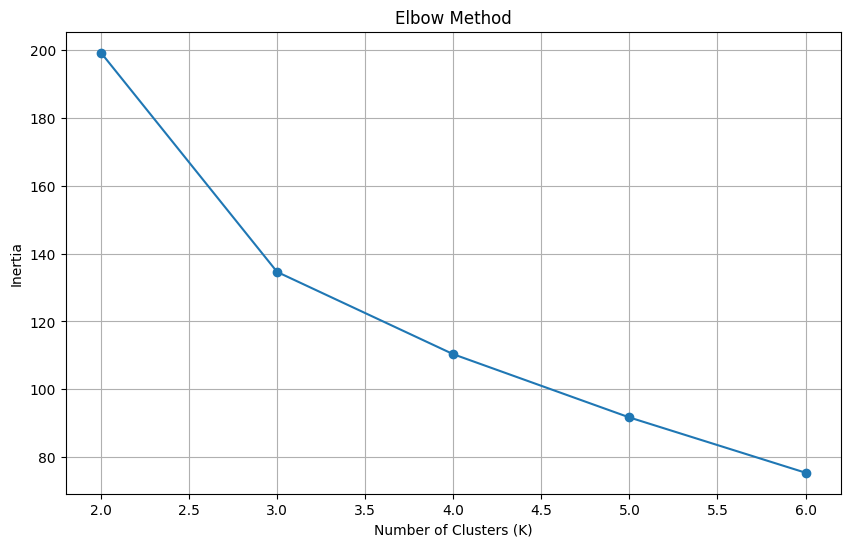

In [ ]:
plt.figure(
    figsize=(10, 6)
)

plt.plot(
    list(K_range),
    inertia,
    marker="o"
)

plt.xlabel(
    "Number of Clusters (K)"
)

plt.ylabel(
    "Inertia"
)

plt.title(
    "Elbow Method"
)

plt.grid(True)

plt.show()

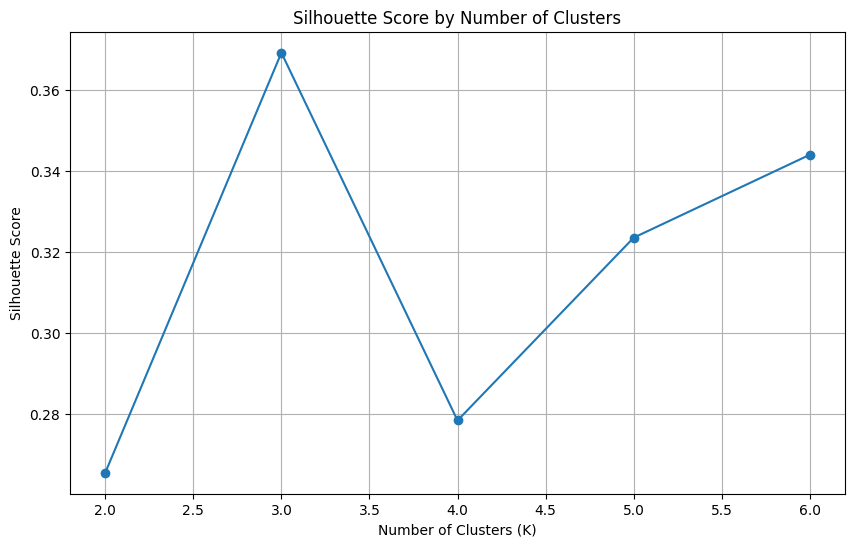

K=2: Silhouette=0.2654
K=3: Silhouette=0.3692
K=4: Silhouette=0.2783
K=5: Silhouette=0.3235
K=6: Silhouette=0.3440


In [ ]:
plt.figure(
    figsize=(10, 6)
)

plt.plot(
    list(K_range),
    silhouette_scores,
    marker="o"
)

plt.xlabel(
    "Number of Clusters (K)"
)

plt.ylabel(
    "Silhouette Score"
)

plt.title(
    "Silhouette Score by Number of Clusters"
)

plt.grid(True)

plt.show()

for k, score in zip(
    K_range,
    silhouette_scores
):

    print(
        f"K={k}: "
        f"Silhouette={score:.4f}"
    )

In [ ]:
best_k = list(K_range)[
    np.argmax(
        silhouette_scores
    )
]

print(
    "Recommended number of clusters:",
    best_k
)

Recommended number of clusters: 3


Train final K-Means

In [ ]:
# ============================================================
# FINAL K-MEANS MODEL
# ============================================================

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=50
)

master["cluster"] = (
    kmeans.fit_predict(
        X_scaled_cleaned
    )
)

print(
    master["cluster"]
    .value_counts()
    .sort_index()
)

cluster
0     6
1    19
2     4
Name: count, dtype: int64


In [ ]:
cluster_profile = (
    master
    .groupby("cluster")[ml_features]
    .mean()
)

display(
    cluster_profile
)

,gdp_per_capita,income_mean,income_median,poverty_score,inequality_score,unemployment_score,labour_participation_rate,forest_per_population,treated_water_access,water_pressure_score
cluster,,,,,,,,,,
0,15.941,"5,837.667","4,389.667",-14.567,-0.387,-5.033,64.300,997.918,79.367,-259.333
1,21.903,"6,923.368","5,527.263",-5.205,-0.350,-3.363,65.695,236.443,99.063,-240.789
2,48.835,"12,816.000","10,064.000",-1.125,-0.367,-3.175,76.000,17.753,99.650,-794.000


In [ ]:
cluster_profile_scaled = (
    pd.DataFrame(
        scaler.transform(
            cluster_profile
        ),
        columns=ml_features,
        index=cluster_profile.index
    )
)

display(
    cluster_profile_scaled
)

,gdp_per_capita,income_mean,income_median,poverty_score,inequality_score,unemployment_score,labour_participation_rate,forest_per_population,treated_water_access,water_pressure_score
cluster,,,,,,,,,,
0,-0.284,-0.701,-0.808,-1.623,-1.085,-0.899,-0.459,1.340,-1.893,0.199
1,-0.083,-0.246,-0.206,0.279,0.405,0.213,-0.206,-0.269,0.481,0.259
2,0.823,2.220,2.193,1.108,-0.298,0.338,1.667,-0.732,0.552,-1.527


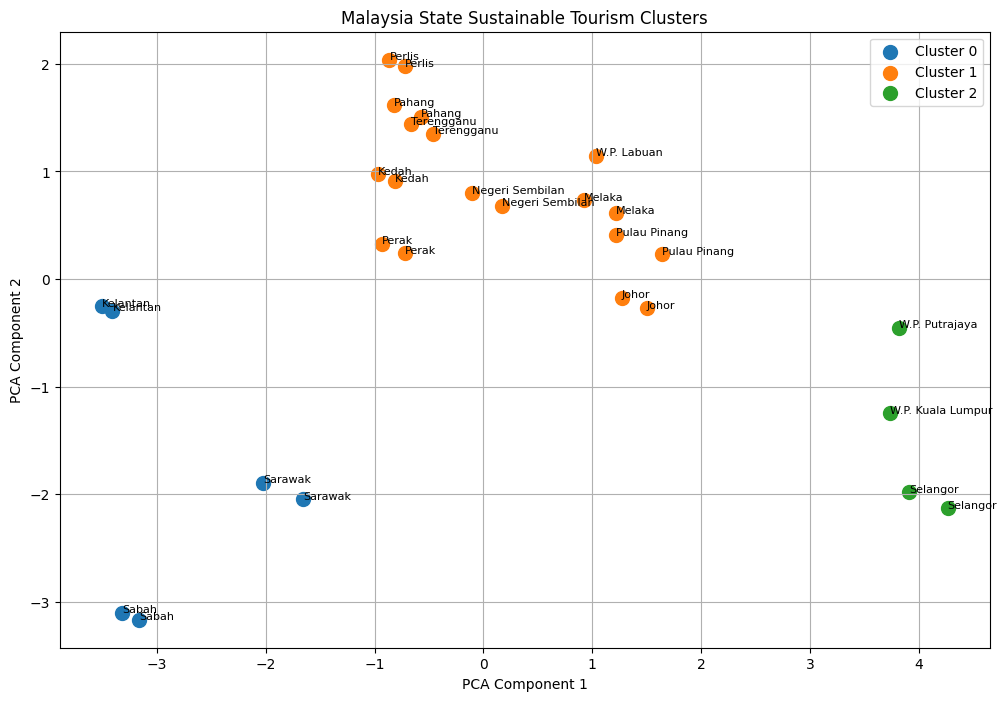

In [ ]:
# ============================================================
# PCA
# ============================================================

pca = PCA(
    n_components=2,
    random_state=42
)

X_pca = pca.fit_transform(
    X_scaled_cleaned
)

master["PCA1"] = X_pca[:, 0]
master["PCA2"] = X_pca[:, 1]

plt.figure(
    figsize=(12, 8)
)

for cluster in sorted(
    master["cluster"].unique()
):

    subset = master[
        master["cluster"] == cluster
    ]

    plt.scatter(
        subset["PCA1"],
        subset["PCA2"],
        label=f"Cluster {cluster}",
        s=100
    )

    for _, row in subset.iterrows():

        plt.annotate(
            row["state"],
            (
                row["PCA1"],
                row["PCA2"]
            ),
            fontsize=8
        )

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")

plt.title(
    "Malaysia State Sustainable Tourism Clusters"
)

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
cluster_states = master[
    [
        "state",
        "cluster"
    ]
].sort_values(
    "cluster"
)

display(
    cluster_states
)

,state,cluster
5,Kelantan,0
4,Kelantan,0
23,Sabah,0
22,Sabah,0
24,Sarawak,0
25,Sarawak,0
0,Johor,1
1,Johor,1
8,Negeri Sembilan,1
9,Negeri Sembilan,1


In [ ]:
# ============================================================
# DIMENSION SCORES
# ============================================================

from sklearn.preprocessing import MinMaxScaler

dimension_scaler = MinMaxScaler()

master["economic_score"] = (
    dimension_scaler.fit_transform(
        master[
            [
                "gdp_per_capita",
                "income_mean",
                "income_median"
            ]
        ]
    ).mean(axis=1) * 100
)

In [ ]:
master["social_score"] = (
    dimension_scaler.fit_transform(
        master[
            [
                "poverty_score",
                "inequality_score",
                "unemployment_score",
                "labour_participation_rate"
            ]
        ]
    ).mean(axis=1) * 100
)

In [ ]:
master["environment_score"] = (
    dimension_scaler.fit_transform(
        master[
            [
                "forest_per_population",
                "treated_water_access",
                "water_pressure_score"
            ]
        ]
    ).mean(axis=1) * 100
)

In [ ]:
# ============================================================
# SUSTAINABLE TOURISM READINESS INDEX
# ============================================================

master["readiness_score"] = (
    master["economic_score"] * 0.3333
    +
    master["social_score"] * 0.3333
    +
    master["environment_score"] * 0.3334
)

master["readiness_score"] = (
    master["readiness_score"]
    .round(2)
)

display(
    master
    .sort_values(
        "readiness_score",
        ascending=False
    )[
        [
            "state",
            "economic_score",
            "social_score",
            "environment_score",
            "readiness_score"
        ]
    ]
)

,state,economic_score,social_score,environment_score,readiness_score
26,W.P. Kuala Lumpur,99.426,61.682,60.523,73.880
28,W.P. Putrajaya,70.682,82.105,60.523,71.100
27,W.P. Labuan,51.961,63.031,66.291,60.430
18,Selangor,75.438,71.345,33.816,60.200
12,Pulau Pinang,45.199,64.545,58.695,56.150
10,Pahang,19.593,70.777,77.941,56.110
19,Selangor,60.590,71.345,33.816,55.250
6,Melaka,37.666,65.558,62.470,55.230
11,Pahang,9.199,70.777,77.941,52.640
0,Johor,40.143,61.760,55.303,52.400


In [ ]:
# ============================================================
# READINESS CATEGORY
# ============================================================

def readiness_category(score):

    if score >= 70:
        return "High"

    elif score >= 50:
        return "Medium"

    else:
        return "Emerging"


master["readiness_category"] = (
    master["readiness_score"]
    .apply(readiness_category)
)

display(
    master[
        [
            "state",
            "readiness_score",
            "readiness_category"
        ]
    ].sort_values(
        "readiness_score",
        ascending=False
    )
)

,state,readiness_score,readiness_category
26,W.P. Kuala Lumpur,73.880,High
28,W.P. Putrajaya,71.100,High
27,W.P. Labuan,60.430,Medium
18,Selangor,60.200,Medium
12,Pulau Pinang,56.150,Medium
10,Pahang,56.110,Medium
19,Selangor,55.250,Medium
6,Melaka,55.230,Medium
11,Pahang,52.640,Medium
0,Johor,52.400,Medium


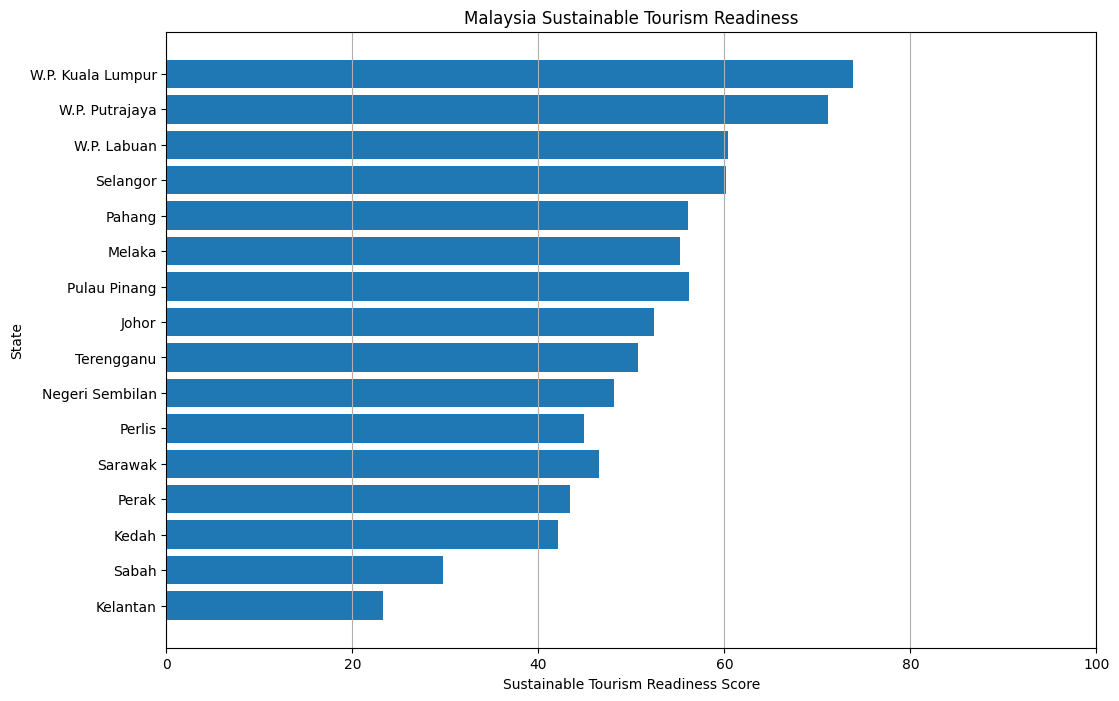

In [ ]:
ranking = (
    master[
        [
            "state",
            "readiness_score"
        ]
    ]
    .sort_values(
        "readiness_score",
        ascending=True
    )
)

plt.figure(
    figsize=(12, 8)
)

plt.barh(
    ranking["state"],
    ranking["readiness_score"]
)

plt.xlabel(
    "Sustainable Tourism Readiness Score"
)

plt.ylabel(
    "State"
)

plt.title(
    "Malaysia Sustainable Tourism Readiness"
)

plt.xlim(
    0,
    100
)

plt.grid(
    axis="x"
)

plt.show()

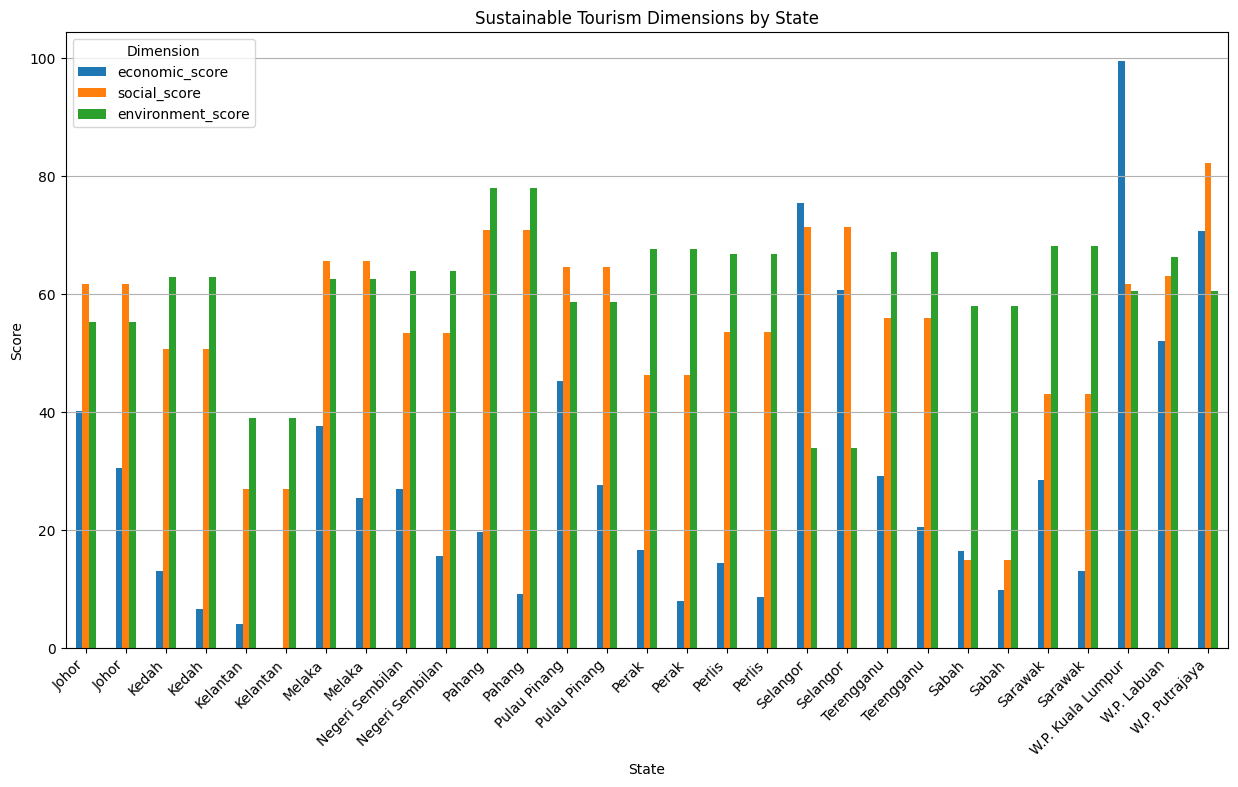

In [ ]:
score_columns = [
    "economic_score",
    "social_score",
    "environment_score"
]

score_by_state = master[
    ["state"] + score_columns
].set_index("state")

score_by_state.plot(
    kind="bar",
    figsize=(15, 8)
)

plt.ylabel(
    "Score"
)

plt.xlabel(
    "State"
)

plt.title(
    "Sustainable Tourism Dimensions by State"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y"
)

plt.legend(
    title="Dimension"
)

plt.show()

ML classification

In [ ]:
# ============================================================
# RANDOM FOREST CLASSIFICATION
# ============================================================

rf_features = ml_features

X_rf = master[
    rf_features
]

y_rf = master[
    "cluster"
]

In [ ]:
rf = RandomForestClassifier(
    n_estimators=500,
    random_state=42,
    class_weight="balanced"
)

rf.fit(
    X_rf,
    y_rf
)

print(
    "Random Forest trained."
)

Random Forest trained.


In [ ]:
importance = pd.DataFrame({

    "feature":
    rf_features,

    "importance":
    rf.feature_importances_

})

importance = (
    importance
    .sort_values(
        "importance",
        ascending=False
    )
)

display(
    importance
)

,feature,importance
3,poverty_score,0.232
4,inequality_score,0.155
8,treated_water_access,0.146
2,income_median,0.134
1,income_mean,0.123
6,labour_participation_rate,0.116
7,forest_per_population,0.042
5,unemployment_score,0.034
9,water_pressure_score,0.013
0,gdp_per_capita,0.006


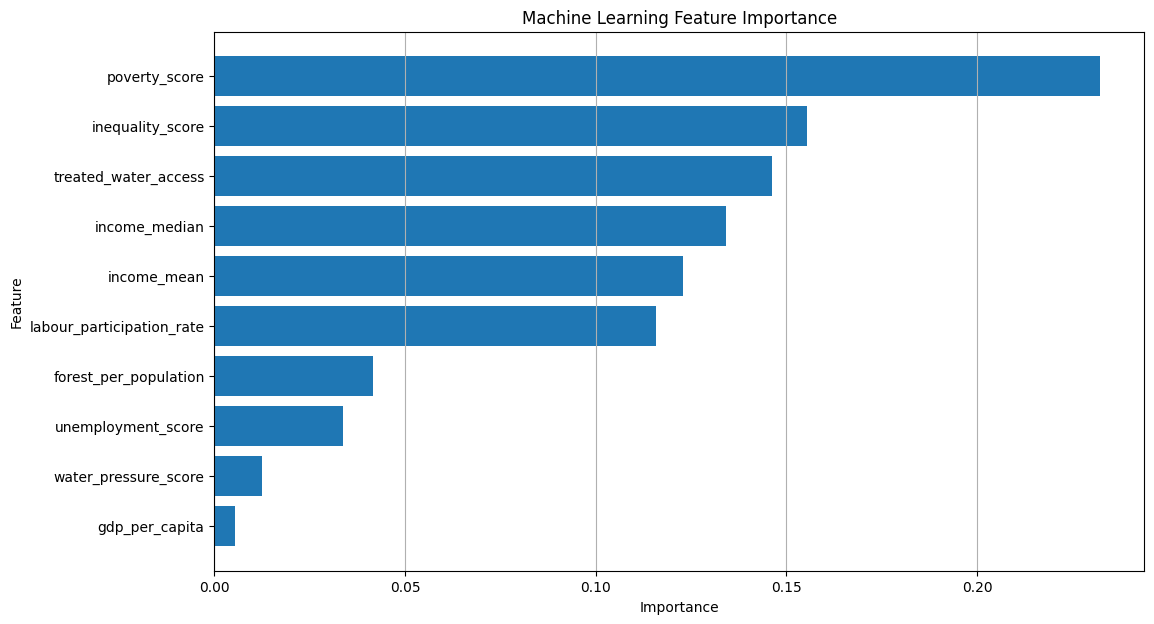

In [ ]:
plt.figure(
    figsize=(12, 7)
)

plt.barh(
    importance["feature"],
    importance["importance"]
)

plt.xlabel(
    "Importance"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Machine Learning Feature Importance"
)

plt.gca().invert_yaxis()

plt.grid(
    axis="x"
)

plt.show()

In [ ]:
# ============================================================
# CLUSTER INTERPRETATION
# ============================================================

cluster_scores = (
    master
    .groupby("cluster")
    [
        [
            "economic_score",
            "social_score",
            "environment_score",
            "readiness_score"
        ]
    ]
    .mean()
)

display(
    cluster_scores
)

,economic_score,social_score,environment_score,readiness_score
cluster,,,,
0,11.936,28.328,55.027,31.767
1,23.498,58.302,64.812,48.872
2,76.534,71.619,47.169,65.108


In [ ]:
cluster_names = {}

for cluster in cluster_scores.index:

    score = (
        cluster_scores
        .loc[
            cluster,
            "readiness_score"
        ]
    )

    if score >= 70:

        cluster_names[
            cluster
        ] = "High Readiness"

    elif score >= 50:

        cluster_names[
            cluster
        ] = "Moderate Readiness"

    else:

        cluster_names[
            cluster
        ] = "Emerging Readiness"


master["cluster_name"] = (
    master["cluster"]
    .map(cluster_names)
)

display(
    master[
        [
            "state",
            "cluster",
            "cluster_name"
        ]
    ]
)

,state,cluster,cluster_name
0,Johor,1,Emerging Readiness
1,Johor,1,Emerging Readiness
2,Kedah,1,Emerging Readiness
3,Kedah,1,Emerging Readiness
4,Kelantan,0,Emerging Readiness
5,Kelantan,0,Emerging Readiness
6,Melaka,1,Emerging Readiness
7,Melaka,1,Emerging Readiness
8,Negeri Sembilan,1,Emerging Readiness
9,Negeri Sembilan,1,Emerging Readiness


Final master dataset

In [ ]:
# ============================================================
# FINAL DATASET
# ============================================================

final_columns = [

    "state",

    # Raw socioeconomic
    "income_mean",
    "income_median",
    "expenditure_mean",
    "gini",
    "poverty",

    # Population
    "population",

    # Economic
    "gdp",
    "gdp_per_capita",

    # Labour
    "unemployment_rate",
    "labour_participation_rate",

    # Environment
    "forest_reserve_area",
    "treated_water_access",
    "domestic_water_consumption",
    "nondomestic_water_consumption",

    # Scores
    "economic_score",
    "social_score",
    "environment_score",
    "readiness_score",
    "readiness_category",

    # ML
    "cluster",
    "cluster_name"
]

final_columns = [
    c for c in final_columns
    if c in master.columns
]

final_dataset = master[
    final_columns
].copy()

display(
    final_dataset
    .sort_values(
        "readiness_score",
        ascending=False
    )
)

,state,income_mean,income_median,expenditure_mean,gini,poverty,gdp,gdp_per_capita,unemployment_rate,labour_participation_rate,forest_reserve_area,treated_water_access,domestic_water_consumption,nondomestic_water_consumption,economic_score,social_score,environment_score,readiness_score,readiness_category,cluster,cluster_name
26,W.P. Kuala Lumpur,13325,10234,7823,0.380,1.400,"240,517.538",122.638,3.800,72.700,68.000,99.500,394.000,238.000,99.426,61.682,60.523,73.880,High,2,Moderate Readiness
28,W.P. Putrajaya,13473,10056,8897,0.368,0.100,"7,086.234",18.071,1.300,77.700,0.000,99.500,394.000,238.000,70.682,82.105,60.523,71.100,High,2,Moderate Readiness
27,W.P. Labuan,8250,6904,4176,0.300,2.500,"7,962.511",82.172,6.900,67.400,0.000,100.000,19.000,33.000,51.961,63.031,66.291,60.430,Medium,1,Emerging Readiness
18,Selangor,12233,9983,6770,0.361,1.500,"385,158.798",54.630,3.800,76.800,"250,208.000",99.800,"2,230.000","1,350.000",75.438,71.345,33.816,60.200,Medium,2,Moderate Readiness
12,Pulau Pinang,8267,6502,5322,0.371,2.000,"112,281.052",64.496,2.700,70.100,"5,387.000",99.900,534.000,334.000,45.199,64.545,58.695,56.150,Medium,1,Emerging Readiness
10,Pahang,5777,4753,4107,0.308,6.300,"61,746.204",38.250,2.300,64.600,"1,588,298.000",98.000,385.000,283.000,19.593,70.777,77.941,56.110,Medium,1,Emerging Readiness
19,Selangor,12233,9983,6770,0.361,1.500,11.900,0.002,3.800,76.800,"250,208.000",99.800,"2,230.000","1,350.000",60.590,71.345,33.816,55.250,Medium,2,Moderate Readiness
6,Melaka,8057,6210,5707,0.370,4.200,"45,579.035",45.190,1.700,69.800,"5,199.000",100.000,228.000,190.000,37.666,65.558,62.470,55.230,Medium,1,Emerging Readiness
11,Pahang,5777,4753,4107,0.308,6.300,11.400,0.007,2.300,64.600,"1,588,298.000",98.000,385.000,283.000,9.199,70.777,77.941,52.640,Medium,1,Emerging Readiness
0,Johor,8517,6879,5342,0.366,4.600,"142,369.692",35.342,3.200,71.100,"334,502.000",99.900,867.000,536.000,40.143,61.760,55.303,52.400,Medium,1,Emerging Readiness


In [ ]:
# ============================================================
# EXPORT POWER BI FILES
# ============================================================

final_dataset.to_csv(
    "outputs/Malaysia_Sustainable_Tourism_Master.csv",
    index=False
)

importance.to_csv(
    "outputs/ML_Feature_Importance.csv",
    index=False
)

cluster_profile.to_csv(
    "outputs/ML_Cluster_Profile.csv"
)

cluster_states.to_csv(
    "outputs/ML_State_Clusters.csv",
    index=False
)

results = pd.DataFrame({
    "Metric": [
        "Number of states",
        "Number of ML clusters",
        "Silhouette score"
    ],

    "Value": [
        master["state"].nunique(),
        best_k,
        max(silhouette_scores)
    ]
})

results.to_csv(
    "outputs/ML_Model_Summary.csv",
    index=False
)

print(
    "Power BI files created."
)

Power BI files created.


In [ ]:
# ============================================================
# ZIP ALL OUTPUTS
# ============================================================

import shutil

shutil.make_archive(
    "Malaysia_Sustainable_Tourism_Project",
    "zip",
    "outputs"
)

print(
    "ZIP created:"
)

print(
    "Malaysia_Sustainable_Tourism_Project.zip"
)

ZIP created:
Malaysia_Sustainable_Tourism_Project.zip


In [ ]:
from google.colab import files

files.download(
    "Malaysia_Sustainable_Tourism_Project.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>